# 第 17 步：连续账户的事后分段稳定性检查

<!-- SNAPSHOT_NOTE -->

## 数据准备说明

本页记录完整快照上的实际运行。通过 GitHub 克隆源码后，先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。

## 目标与本步能回答的问题

第 16 步已经展示完整历史的策略和基准净值。本步不重新选择窗口、不重新建仓，也不把各年份各自重跑成新的 100 万元账户。只读取第 16 步一倍成本的两条连续账户，按照已经保存的配置切出开发期、验证期和测试期，再检查各段的收益、风险和相对表现。

因此，我把本步定位为“事后分段稳定性检查”。完整 2020—2025 年曲线已经展示，文件名里的 `test` 不会自动让数据重新变成未见样本。结果可以描述当前规则在哪些时期表现较好或较差，但不能因测试段相对领先，反过来选择参数后再称它为独立验证。

## 固定输入与运行命令

输入为 [第 16 步冻结配置](../../runs/first_demo_20261107/lesson16_benchmark_cost/config_snapshot.json) 和同目录下的两份连续账户：

- [策略一倍成本日表](../../runs/first_demo_20261107/lesson16_benchmark_cost/strategy_cost1/daily.csv)。
- [基准一倍成本日表](../../runs/first_demo_20261107/lesson16_benchmark_cost/benchmark_cost1/daily.csv)。

在仓库根目录运行：

```powershell
.\.venv\Scripts\python.exe examples/17_split_stability.py
```

先完成第 16 步，使两份账户与配置来自同一次实验。本脚本只导入指标函数，不调用 `run_backtest`，也不重新计算选股结果。方法文件保存输入账户和配置的哈希，便于确认本次分段具体使用了哪些文件。

分区为开发期 2020—2022 年、验证期 2023 年、测试期 2024—2025 年。日期边界是自然日，实际行数由模拟日历决定：783、260、523，合计 1566。各段时长不同，比较时不能只看原始累计收益。

![事后分段图](../../runs/first_demo_20261107/lesson17_split_stability/split_stability.png)

图的上方每段都把“首条收益之前的权益”展示为 1，便于比较不同阶段的增长路径；这不表示在段首清仓、取款或重新注入现金。图的下方分别比较同段复合年化收益与局部最大回撤。

## 为什么必须保留每段第一条收益

设一段的第一条账户记录是 $a$，它之前的实际账户权益为 $E_{a-1}$。本段展示净值定义为：

$$
W_{a:t}=\prod_{u=a}^{t}(1+r_u)=\frac{E_t}{E_{a-1}}.
$$

如果这是整个账户的第一段，用最初的 100 万元作为 $E_{a-1}$；其他段使用紧邻上一交易日的真实权益。第一条段内收益 $r_a$ 仍然保留，因为它反映旧持仓跨入新年份后的涨跌、可能的调仓与费用。

取出 2023 年数据后，不能对 `equity` 重新做 `pct_change()`，再把第一行缺失值填为零。那样分母会变成第一天收盘权益，删除第一天已经发生的损益。跨年时仍持有的股票，并不会因为图表换了一个面板而消失。

先用 `read_continuous_account` 检查原账户：

```python
previous_equity = daily["equity"].shift(1)
previous_equity.iloc[0] = initial_cash
np.testing.assert_allclose(daily["return"], daily["equity"] / previous_equity - 1,
                           rtol=0, atol=1e-12)
```

第一行对齐前一收盘权益，第二行只为整个账户起点提供已知初始资金，第三行核对已经保存的日收益。这里是在分段之前发现不一致，不是修改原收益。账户日期还必须与冻结配置对应的完整日历一致，不能默许缺日或重复。

## 起点权益与局部回撤

`split_account` 先找到分区第一行在完整账户中的位置，再取其前一行作为锚点。核心逻辑是：

```python
anchor = daily.iloc[first_position - 1]
anchor_equity = float(anchor["equity"])
block["period_nav"] = (1 + block["return"]).cumprod(skipna=False)
block["period_peak"] = block["period_nav"].cummax(skipna=False).clip(lower=1.0)
block["period_drawdown"] = block["period_nav"] / block["period_peak"] - 1
```

前两行读取旧账户的锚点；如果是完整账户第一行，则由专门分支使用初始资金，不能取到表尾。第三行把原有段内收益连乘，第四行把段前财富 1 纳入局部高点，第五行计算这段从起点开始的回撤。

每段仍使用 $N$ 条日收益、252 日复合年化和样本标准差年化。局部最大回撤定义为这段自己的历史高点到低点的跌幅，不延续 2020 年以来的全期高点。它适合描述阶段内经历，但不能把三段回撤相加，或者简单取三段最大值来还原全期最大回撤。

## 两个跨年边界的手工核对

[boundaries.csv](../../runs/first_demo_20261107/lesson17_split_stability/boundaries.csv) 中的实际金额如下：

| 组合与段首 | 段前权益 | 首日收盘权益 | 首日收益 |
| --- | ---: | ---: | ---: |
| 策略，2023-01-02 | 909916.4622141232 | 907042.5470577856 | -0.3158438467% |
| 基准，2023-01-02 | 1172419.9690753247 | 1175618.927354411 | 0.2728508865% |
| 策略，2024-01-01 | 951442.1404445647 | 943376.7724242980 | -0.8476992638% |
| 基准，2024-01-01 | 1247032.137333443 | 1240626.1023196182 | -0.5137024798% |

这些日期来自人工工作日日历，不代表真实元旦是否开市。策略验证段的第一笔展示净值应是 `0.996841561533`，测试段第一笔应是 `0.991523007362`，都不应被强制改成 1。图中的额外起点 1 画在段前锚点，只提供展示基准，不删除首日收益。

`anchor_holdings_count` 也一并保存。例如策略进入验证期时有 9 只股票，进入测试期时有 10 只；基准均有 40 只。这些已有仓位继续承担后续价格变化，分段计算没有重新从空仓开始。

## 六组阶段指标

以下结果中的收益与波动在 CSV 中以小数保存，在本表转换为百分数；费用为对应连续账户在该段实际记录的合计。

| 组合与区间 | N | 累计收益 | 252 日年化 | 年化波动 | 最大回撤幅度 | 成本（元） |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 策略开发期 | 783 | -9.0084% | -2.9926% | 13.1030% | 16.9879% | 47629.2339 |
| 策略验证期 | 260 | 4.5637% | 4.4202% | 14.5978% | 12.3059% | 13834.5626 |
| 策略测试期 | 523 | 1.3586% | 0.6523% | 13.8422% | 25.1816% | 31741.6230 |
| 基准开发期 | 783 | 17.2420% | 5.2528% | 12.4236% | 10.6735% | 2904.7542 |
| 基准验证期 | 260 | 6.3639% | 6.1622% | 13.7630% | 9.7940% | 812.3273 |
| 基准测试期 | 523 | -8.4561% | -4.1678% | 12.6650% | 20.7582% | 1633.0086 |

[comparison.csv](../../runs/first_demo_20261107/lesson17_split_stability/comparison.csv) 给出同段比较：

| 阶段 | 累计收益差 | 比值相对收益 |
| --- | ---: | ---: |
| 开发期 | -26.2504 个百分点 | -22.3899% |
| 验证期 | -1.8003 个百分点 | -1.6926% |
| 测试期 | 9.8147 个百分点 | 10.7213% |

策略只在三段中的一段相对领先，而且测试段自身仍出现约 25.18% 的局部最大回撤。我不会因期末略有正收益就忽略期间下行风险，也不能把最后一段相对领先解释为跨时期稳定有效的证明。

## 将分段结果还原为完整历史

收益可以通过增长倍数连乘：

$$
1+R_{all}=\prod_{k=1}^{3}(1+R_k).
$$

关键代码是：

```python
reconstructed_return = (1 + periods["total_return"]).prod() - 1
np.testing.assert_allclose(reconstructed_return, whole["total_return"],
                           rtol=0, atol=1e-10)
```

第一行将各段收益转换成倍数相乘，第二行与完整连续账户指标核对。策略段乘积约为 `0.964367991381`，基准约为 `1.141581247538`，分别还原全期 -3.5632% 与 14.1581%。策略费用段和为 `93205.4194780295`，基准为 `5350.090081438499`，日期数合计都是 1566。

相对财富也可以按各段比值的增长倍数连乘，最终相对收益约 -15.5235%。直接把 -22.3899%、-1.6926% 与 10.7213% 相加，无法代替这个结果。回撤和年化波动则依赖路径与统计定义，不能照搬收益的连乘规则。

## 证据文件、误区与验收

[metrics.csv](../../runs/first_demo_20261107/lesson17_split_stability/metrics.csv) 保存六组区间指标；[period_paths.csv](../../runs/first_demo_20261107/lesson17_split_stability/period_paths.csv) 保留原始账户列及 `period_nav/period_peak/period_drawdown`；[reconciliation.csv](../../runs/first_demo_20261107/lesson17_split_stability/reconciliation.csv) 保存跨段核对；[methodology.json](../../runs/first_demo_20261107/lesson17_split_stability/methodology.json) 明确记录事后检查和来源哈希。

验收包括：配置来自第 16 步冻结快照；三个区间不重叠也不遗漏；原始首日收益与前日权益关系成立；段内净值等于当前权益除以段前权益；局部回撤初始高点为 1；各段增长倍数与费用能还原全期。重新注资、清仓或丢首行虽然可能使表格更整齐，却会改变原有账户含义。

## 结论边界与下一步

当前人工样本中的表现明显依赖时间区间，尚不能据此声称完成严格未见样本外验证。真正的保留测试需要在观察测试绩效前冻结方向、窗口、股票池、费用与组合规则，在开发和验证阶段作有限决策后再评估保留段。若反复查看同一测试段并据此改规则，就需要新的未使用区间或严格外层滚动评估。

跨段保留过去的价格历史、已有持仓和前日权益，本身是正常时间推进，不是未来泄漏。真正需要防止的是用后来的表现倒选当时规则。下一步将同一套工程接到真实行情快照，先查数据和成交假设，再解释绩效。

[完整脚本](../../examples/17_split_stability.py) · [下一步：真实行情接入](../18_real_market_data/README.md)

## 完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/17_split_stability.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
r"""第十七课：连续账户的事后分段稳定性检查。

运行：.\.venv\Scripts\python.exe examples/17_split_stability.py
读取第十六课 1 倍成本结果，不重新清仓、注资或调参。
"""

from hashlib import sha256
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

from ashare_lab.backtest import metrics
from ashare_lab.config import load_config
from ashare_lab.data import write_json


SPLIT_LABELS = {"development": "开发期", "validation": "验证期", "test": "测试期"}

### 完整实现 · 单元 2

In [3]:
def read_continuous_account(path, initial_cash, expected_dates):
    """检查账户收益以初始资金/前一日权益为基准；不填补缺失日收益。"""
    daily = pd.read_csv(path, parse_dates=["date"])
    daily = daily.sort_values("date").reset_index(drop=True)
    if daily.empty or daily["date"].duplicated().any():
        raise ValueError("账户记录为空或日期重复。")
    pd.testing.assert_index_equal(pd.DatetimeIndex(daily["date"]), expected_dates,
                                  check_names=False, check_exact=True)
    values = daily[["equity", "nav", "return", "cash", "cost"]].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (daily["equity"] <= 0).any() or (daily["return"] <= -1).any():
        raise ValueError("账户金额或日收益缺失/非法，停止分段。")
    previous_equity = daily["equity"].shift(1)
    previous_equity.iloc[0] = initial_cash
    np.testing.assert_allclose(daily["return"], daily["equity"] / previous_equity - 1,
                               rtol=0, atol=1e-12)
    np.testing.assert_allclose(daily["nav"], daily["equity"] / initial_cash,
                               rtol=0, atol=1e-12)
    return daily

### 完整实现 · 单元 3

In [4]:
def split_account(daily, split, bounds, initial_cash):
    """保留区间首条收益；展示净值以首条收益之前的权益为 1。"""
    start, end = map(pd.Timestamp, bounds)
    mask = daily["date"].between(start, end, inclusive="both")
    block = daily.loc[mask].copy()
    if block.empty:
        raise ValueError(f"{split} 没有账户记录。")

    # 这些是连续账户的上一日基准，不是在分段开始时注入的新资金。
    first_position = np.flatnonzero(mask.to_numpy())[0]
    if first_position == 0:
        anchor_equity = initial_cash
        anchor_date = None
        anchor_holdings = 0
    else:
        anchor = daily.iloc[first_position - 1]
        anchor_equity = float(anchor["equity"])
        anchor_date = anchor["date"]
        anchor_holdings = int(anchor["holdings_count"])

    # 本课核心：切的是已有日收益，不对切片重新 pct_change 或把首条收益填零。
    block["period_nav"] = (1 + block["return"]).cumprod(skipna=False)
    block["period_peak"] = block["period_nav"].cummax(skipna=False).clip(lower=1.0)
    block["period_drawdown"] = block["period_nav"] / block["period_peak"] - 1
    values = metrics(block)

    np.testing.assert_allclose(block["period_nav"], block["equity"] / anchor_equity,
                               rtol=0, atol=1e-10)
    np.testing.assert_allclose(block["period_drawdown"].min(), values["max_drawdown"],
                               rtol=0, atol=1e-10)
    signed_drawdown = values.pop("max_drawdown")
    row = dict(split=split, label=SPLIT_LABELS.get(split, split), requested_start=str(start.date()),
               requested_end=str(end.date()), first_date=str(block["date"].iloc[0].date()),
               last_date=str(block["date"].iloc[-1].date()), n_days=len(block), **values,
               max_drawdown=-signed_drawdown, max_drawdown_signed=signed_drawdown,
               anchor_equity=float(anchor_equity), ending_equity=float(block["equity"].iloc[-1]))
    boundary = dict(split=split, anchor_date=anchor_date, anchor_equity=float(anchor_equity),
                    anchor_holdings_count=anchor_holdings, first_date=block["date"].iloc[0],
                    first_day_return=float(block["return"].iloc[0]),
                    first_close_equity=float(block["equity"].iloc[0]),
                    last_date=block["date"].iloc[-1], ending_equity=float(block["equity"].iloc[-1]))
    block["split"] = split
    return block, row, boundary

### 完整实现 · 单元 4

In [5]:
def compare_periods(metric_table, paths, splits):
    """以相同区间配对；收益差用百分点，比例比较用相对财富。"""
    rows, relative_frames = [], []
    for split in splits:
        selected = metric_table.loc[metric_table["split"].eq(split)].set_index("portfolio")
        strategy_return = float(selected.loc["strategy", "total_return"])
        benchmark_return = float(selected.loc["benchmark", "total_return"])
        return_gap_pp = (strategy_return - benchmark_return) * 100
        relative_return = (1 + strategy_return) / (1 + benchmark_return) - 1
        rows.append(dict(split=split, label=SPLIT_LABELS.get(split, split),
                         n_days=int(selected.loc["strategy", "n_days"]),
                         strategy_total_return=strategy_return, benchmark_total_return=benchmark_return,
                         return_gap_percentage_points=return_gap_pp, relative_return=relative_return,
                         strategy_annual_return=float(selected.loc["strategy", "annual_return"]),
                         benchmark_annual_return=float(selected.loc["benchmark", "annual_return"]),
                         strategy_max_drawdown=float(selected.loc["strategy", "max_drawdown"]),
                         benchmark_max_drawdown=float(selected.loc["benchmark", "max_drawdown"])))
        strategy = paths.loc[paths["split"].eq(split) & paths["portfolio"].eq("strategy"),
                             ["date", "period_nav"]].rename(columns={"period_nav": "strategy_period_nav"})
        benchmark = paths.loc[paths["split"].eq(split) & paths["portfolio"].eq("benchmark"),
                              ["date", "period_nav"]].rename(columns={"period_nav": "benchmark_period_nav"})
        pair = strategy.merge(benchmark, on="date", how="inner", validate="one_to_one")
        assert len(pair) == len(strategy) == len(benchmark)
        pair["relative_nav"] = pair["strategy_period_nav"] / pair["benchmark_period_nav"]
        pair["relative_return"] = pair["relative_nav"] - 1
        pair["split"] = split
        np.testing.assert_allclose(pair["relative_return"].iloc[-1], relative_return, rtol=0, atol=1e-10)
        relative_frames.append(pair)
    return pd.DataFrame(rows), pd.concat(relative_frames, ignore_index=True)

### 完整实现 · 单元 5

In [6]:
def reconcile_segments(accounts, metric_table, comparison):
    """相邻区间收益连乘、费用求和；回撤不做跨段求和或取最大值。"""
    rows = []
    for portfolio, daily in accounts.items():
        periods = metric_table.loc[metric_table["portfolio"].eq(portfolio)]
        reconstructed_return = (1 + periods["total_return"]).prod() - 1
        whole = metrics(daily)
        np.testing.assert_allclose(reconstructed_return, whole["total_return"], rtol=0, atol=1e-10)
        np.testing.assert_allclose(periods["total_cost"].sum(), whole["total_cost"], rtol=0, atol=1e-7)
        assert periods["n_days"].sum() == len(daily)
        rows.append(dict(portfolio=portfolio, n_days=len(daily),
                         compounded_segment_return=float(reconstructed_return),
                         full_history_return=float(whole["total_return"]),
                         full_history_max_drawdown=float(-whole["max_drawdown"]),
                         summed_segment_cost=float(periods["total_cost"].sum()),
                         full_history_cost=float(whole["total_cost"])))
    strategy_total = metrics(accounts["strategy"])["total_return"]
    benchmark_total = metrics(accounts["benchmark"])["total_return"]
    np.testing.assert_allclose((1 + comparison["relative_return"]).prod() - 1,
                               (1 + strategy_total) / (1 + benchmark_total) - 1, rtol=0, atol=1e-10)
    return pd.DataFrame(rows)

### 完整实现 · 单元 6

In [7]:
def plot_stability(paths, metric_table, boundaries, splits, output_path):
    """同一幅图展示分段净值、复合年化收益和区间内最大回撤。"""
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams["font.size"] = 11
    fig = plt.figure(figsize=(13, 8.5), layout="constrained")
    grid = fig.add_gridspec(2, 6, height_ratios=[1.1, 1])
    fig.suptitle("开发、验证、测试：事后分段检查（模拟数据，1 倍成本）", fontsize=17)
    nav_min = min(1.0, paths["period_nav"].min()) - 0.05
    nav_max = max(1.0, paths["period_nav"].max()) + 0.17
    for number, split in enumerate(splits):
        ax = fig.add_subplot(grid[0, number * 2:number * 2 + 2])
        block = paths.loc[paths["split"].eq(split)]
        dates = pd.DatetimeIndex(sorted(block["date"].unique()))
        ax.set_title(f"{SPLIT_LABELS.get(split, split)}\n{dates[0]:%Y-%m-%d} 至 {dates[-1]:%Y-%m-%d}，N={len(dates)}",
                     fontsize=11, pad=12)
        for portfolio, color, line, label in [
            ("strategy", "#3268A8", "-", "三因子策略"),
            ("benchmark", "#747D86", "--", "同池等权基准"),
        ]:
            local = block.loc[block["portfolio"].eq(portfolio)]
            boundary = boundaries.loc[boundaries["split"].eq(split) &
                                        boundaries["portfolio"].eq(portfolio)].iloc[0]
            anchor_date = boundary["anchor_date"]
            if pd.isna(anchor_date):
                anchor_date = local["date"].iloc[0]
            x_values = [anchor_date, *local["date"].tolist()]
            y_values = [1.0, *local["period_nav"].tolist()]
            ax.plot(x_values, y_values, color=color, linestyle=line, linewidth=1.5, label=label)
        ax.axhline(1, color="#9FA6AD", linestyle=":", linewidth=0.8)
        ax.set_ylim(nav_min, nav_max)
        if number == 0:
            ax.set_ylabel("区间净值（段前权益 = 1）")
        else:
            ax.tick_params(labelleft=False)
        ax.set_xticks([dates[0], dates[len(dates) // 2], dates[-1]])
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        ax.legend(loc="upper left", frameon=False, fontsize=10)
        ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="both", labelsize=10)

    labels = [SPLIT_LABELS.get(split, split) for split in splits]
    x_positions = np.arange(len(labels))
    for column, field, title in [
        (0, "annual_return", "复合年化收益（252 交易日口径）"),
        (3, "max_drawdown", "区间内最大回撤幅度（正数）"),
    ]:
        ax = fig.add_subplot(grid[1, column:column + 3])
        all_values = []
        for portfolio, offset, color, edge, hatch, label in [
            ("strategy", -0.18, "#3268A8", "#3268A8", None, "三因子策略"),
            ("benchmark", 0.18, "#D1D5DA", "#747D86", "//", "同池等权基准"),
        ]:
            values = metric_table.loc[metric_table["portfolio"].eq(portfolio)].set_index("split").loc[list(splits), field]
            all_values.extend(values.tolist())
            bars = ax.bar(x_positions + offset, values, width=0.34, color=color, edgecolor=edge,
                           linewidth=0.8, hatch=hatch, label=label)
            ax.bar_label(bars, labels=[f"{value:.2%}" for value in values], padding=4, fontsize=10)
        if field == "annual_return":
            ax.set_ylim(min(0, min(all_values)) - 0.025, max(0, max(all_values)) + 0.05)
        else:
            ax.set_ylim(0, max(all_values) * 1.4)
        ax.axhline(0, color="#747D86", linewidth=0.8)
        ax.set_xticks(x_positions, labels)
        ax.set_title(title, fontsize=12, pad=12)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.legend(loc="upper left", ncol=2, frameon=False, fontsize=10)
        ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    fig.supxlabel("账户连续持仓；上方分段净值以段前权益归一化；各段时长不同，回撤受观察长度影响", fontsize=10)
    fig.savefig(output_path, dpi=180)
    plt.close(fig)

### 完整实现 · 单元 7

In [8]:
def main():
    project_dir = Path(__file__).resolve().parents[1]
    run_dir = project_dir / "runs" / "first_demo_20261107"
    source_dir = run_dir / "lesson16_benchmark_cost"
    output_dir = run_dir / "lesson17_split_stability"

    # 1. 读取上一课冻结配置和已运行的连续账户。
    config_path = source_dir / "config_snapshot.json"
    config = load_config(config_path)
    splits = config["splits"]
    calendar = pd.read_csv(run_dir / "input" / "calendar.csv", parse_dates=["date"])
    expected = pd.DatetimeIndex(calendar.loc[calendar["date"].between(config["start"], config["end"]), "date"])
    accounts, lineage = {}, {}
    for portfolio in ["strategy", "benchmark"]:
        path = source_dir / f"{portfolio}_cost1" / "daily.csv"
        accounts[portfolio] = read_continuous_account(path, config["initial_cash"], expected)
        lineage[portfolio] = dict(path=str(path), sha256=sha256(path.read_bytes()).hexdigest())
    pd.testing.assert_series_equal(accounts["strategy"]["date"], accounts["benchmark"]["date"])

    # 2. 按原定日期切分日收益；不清仓、不重置账户、不重新计算分段首日收益。
    metric_rows, path_frames, boundary_rows = [], [], []
    for portfolio, daily in accounts.items():
        coverage = np.zeros(len(daily), dtype=int)
        for split, bounds in splits.items():
            coverage += daily["date"].between(*bounds).to_numpy(dtype=int)
            block, row, boundary = split_account(daily, split, bounds, config["initial_cash"])
            row["portfolio"] = portfolio
            boundary["portfolio"] = portfolio
            block["portfolio"] = portfolio
            metric_rows.append(row)
            path_frames.append(block)
            boundary_rows.append(boundary)
        if not (coverage == 1).all():
            raise ValueError("各分区必须恰好覆盖完整账户一次，不能遗漏或重叠日期。")

    # 3. 同期配对与跨段对账。
    metric_table = pd.DataFrame(metric_rows)
    paths = pd.concat(path_frames, ignore_index=True)
    boundaries = pd.DataFrame(boundary_rows)
    comparison, relative_paths = compare_periods(metric_table, paths, splits)
    reconciliation = reconcile_segments(accounts, metric_table, comparison)

    # 4. 保存来源和计算过程。收益以小数存储，百分点字段已乘以 100。
    output_dir.mkdir(parents=True, exist_ok=True)
    for name, frame in [("metrics", metric_table), ("period_paths", paths),
                        ("boundaries", boundaries), ("comparison", comparison),
                        ("relative_paths", relative_paths), ("reconciliation", reconciliation)]:
        frame.to_csv(output_dir / f"{name}.csv", index=False, date_format="%Y-%m-%d")
    write_json(output_dir / "config_snapshot.json", config)
    write_json(output_dir / "methodology.json", dict(
        source="synthetic teaching data; weekday calendar, not an A-share exchange calendar",
        evaluation="retrospective split stability check; full history has already been viewed",
        rules="frozen lesson16 config and cost1 accounts; no parameter selection or backtest rerun",
        partitions=splits, annual_sessions=252,
        local_nav="cumprod(1 + original daily returns); equivalent to equity / preceding session equity",
        boundary="retain first included return, prior holdings and prior equity; initial capital for first segment",
        drawdown="local high-water mark starts at 1; segment drawdowns do not reconstruct full-history drawdown",
        comparison="same dates and cost1; total-return difference in percentage points; relative wealth ratio minus 1",
        caution="three unequal-length periods are descriptive, not proof of stability or an untouched holdout",
        positive_relative_periods=int(comparison["relative_return"].gt(0).sum()),
        number_of_periods=len(comparison), inputs=lineage,
        config_sha256=sha256(config_path.read_bytes()).hexdigest(),
    ))
    plot_stability(paths, metric_table, boundaries, splits, output_dir / "split_stability.png")

    print("事后分段检查：人工数据，1 倍教学成本，账户连续持仓。")
    print("\n六组区间指标（收益/回撤以小数存储）：")
    print(metric_table[["split", "portfolio", "n_days", "total_return", "annual_return",
                        "annual_volatility", "max_drawdown", "total_cost"]].to_string(index=False))
    print("\n同期比较：")
    print(comparison.to_string(index=False))
    print("\n边界账户核对：")
    print(boundaries.to_string(index=False))
    print("\n跨段复原全期：")
    print(reconciliation.to_string(index=False))
    print("\n本课结果目录：", output_dir)

### 完整实现 · 单元 8

In [9]:
if __name__ == "__main__":
    main()

事后分段检查：人工数据，1 倍教学成本，账户连续持仓。

六组区间指标（收益/回撤以小数存储）：
      split portfolio  n_days  total_return  annual_return  annual_volatility  max_drawdown   total_cost
development  strategy     783     -0.090084      -0.029926           0.131030      0.169879 47629.233879
 validation  strategy     260      0.045637       0.044202           0.145978      0.123059 13834.562626
       test  strategy     523      0.013586       0.006523           0.138422      0.251816 31741.622973
development benchmark     783      0.172420       0.052528           0.124236      0.106735  2904.754167
 validation benchmark     260      0.063639       0.061622           0.137630      0.097940   812.327323
       test benchmark     523     -0.084561      -0.041678           0.126650      0.207582  1633.008591

同期比较：
      split label  n_days  strategy_total_return  benchmark_total_return  return_gap_percentage_points  relative_return  strategy_annual_return  benchmark_annual_return  strategy_max_drawdown  benchmark_max_dr

## 图表输出

完整脚本已经保存图表。这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

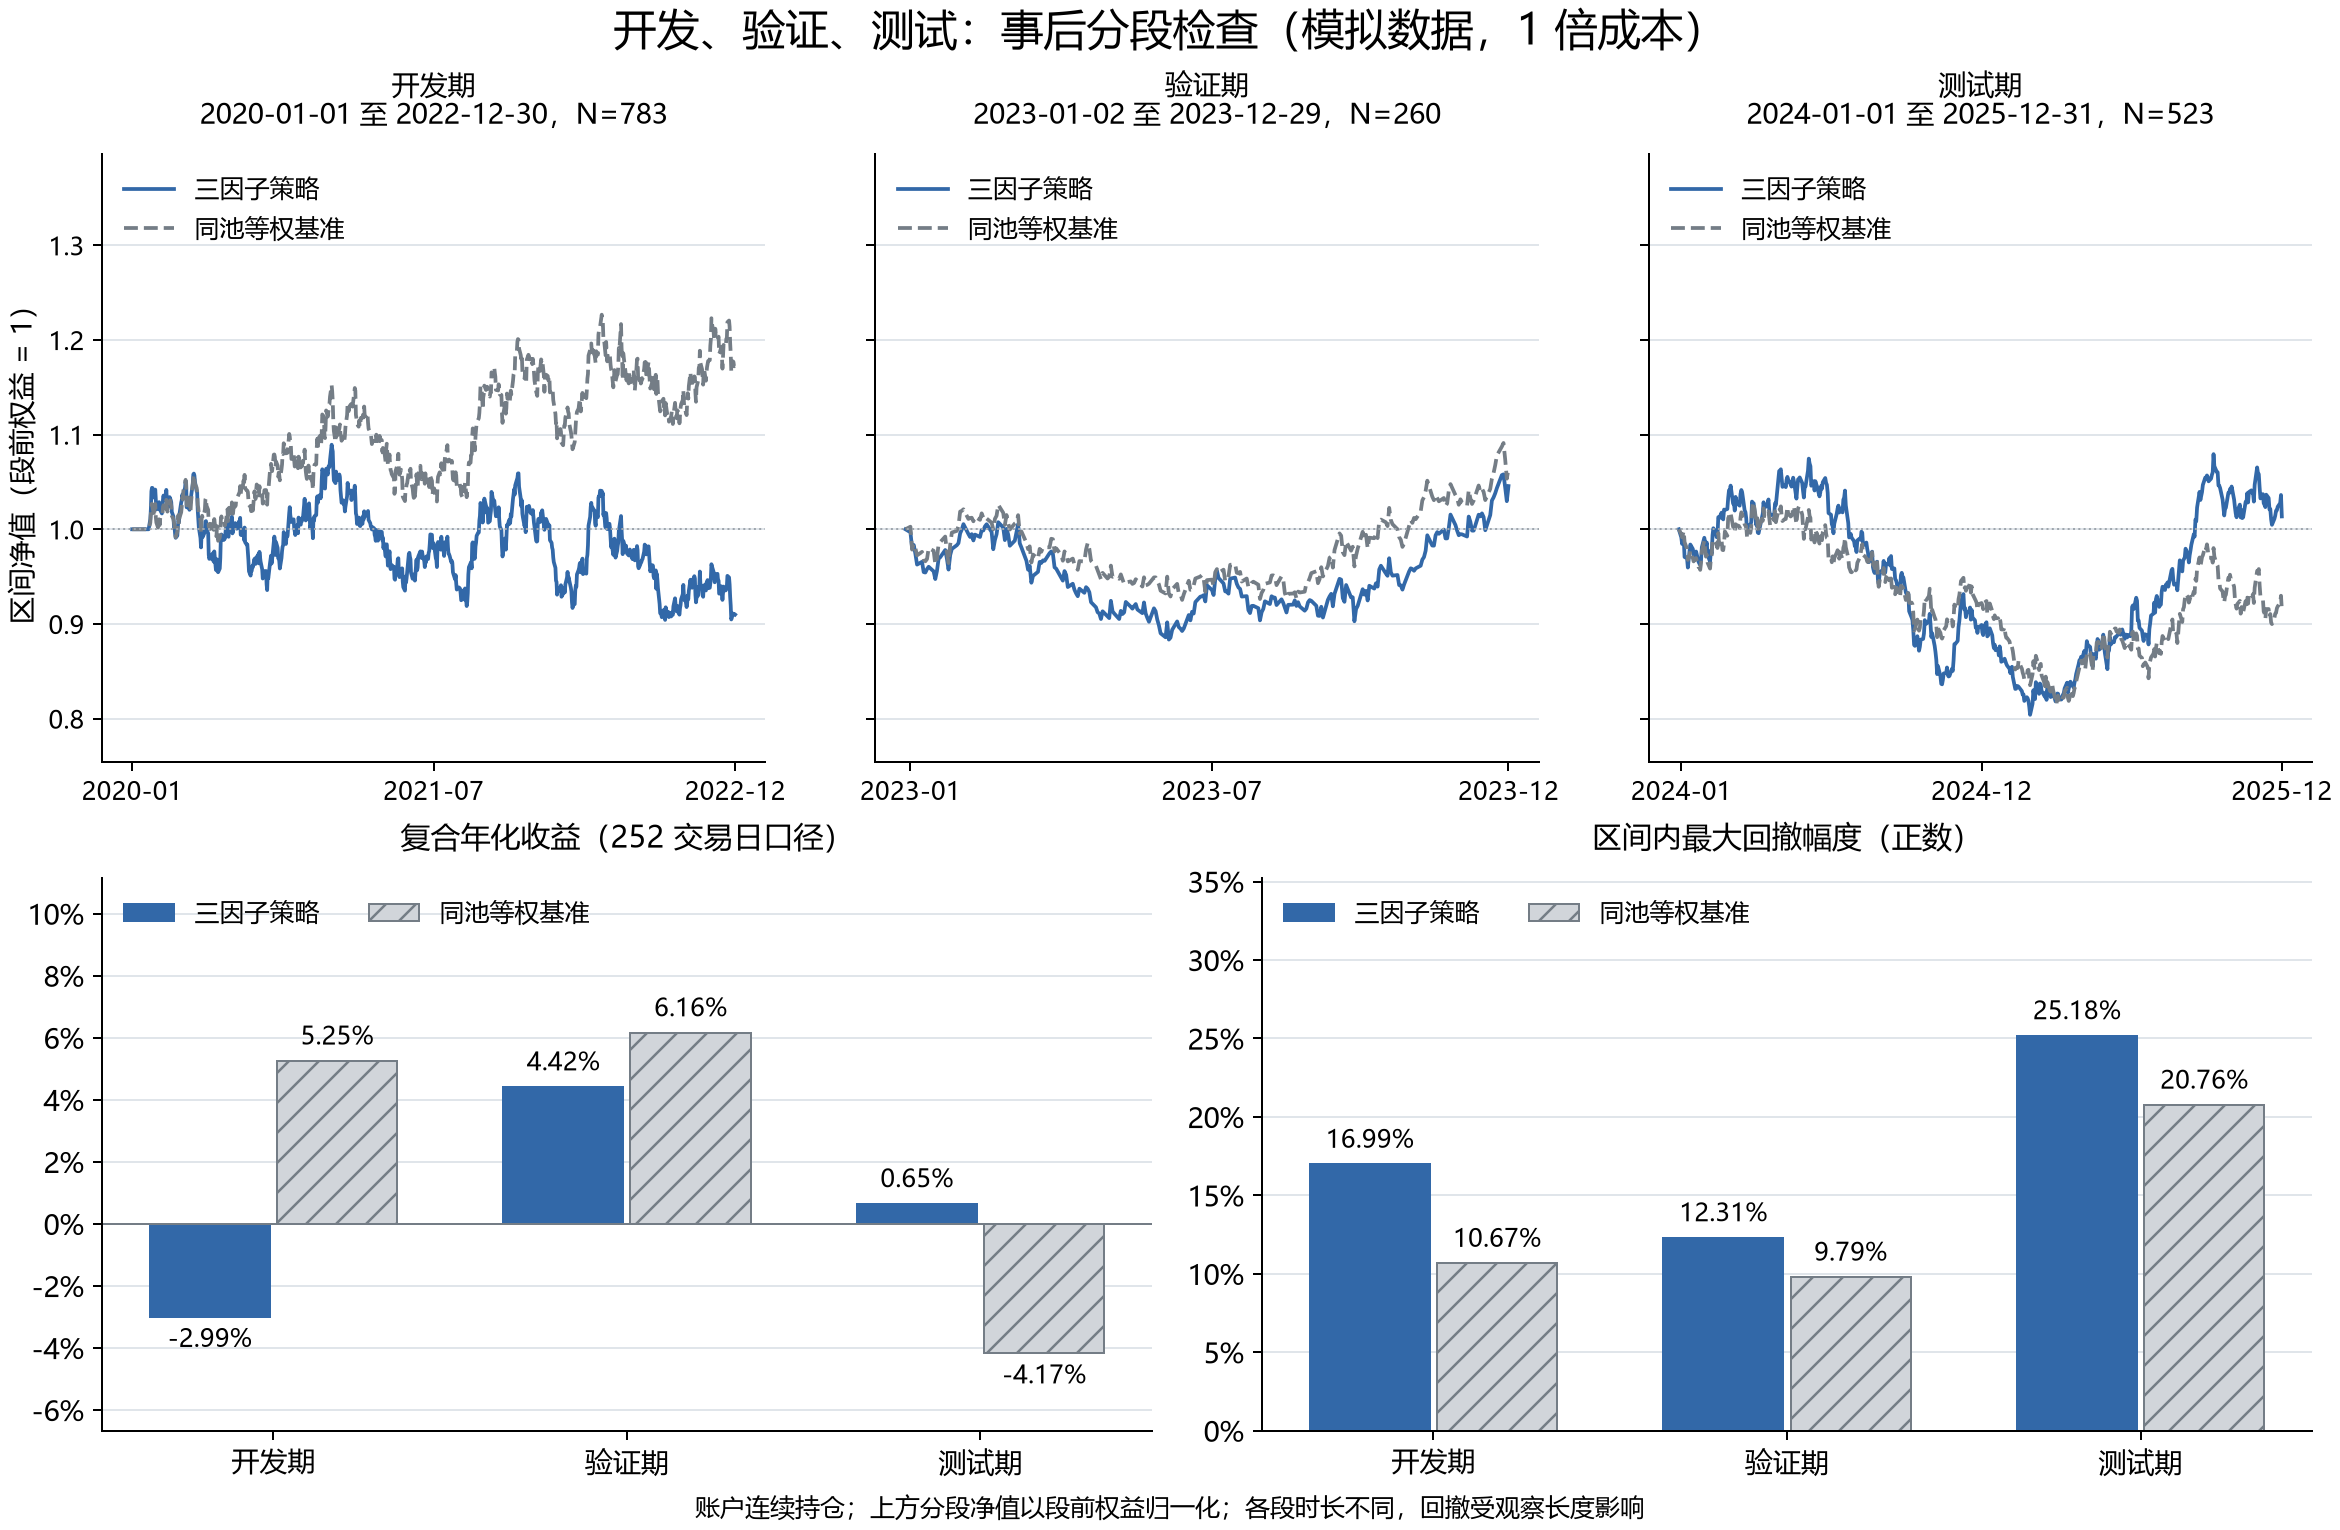

In [10]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson17_split_stability/split_stability.png')))

## 运行复核

以上实现已在干净内核中按顺序执行；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。